# Tuning SVM LINEAR dengan Feature Engineering

Eksperimen `svm_linear_tuning` — Akram, Kelompok 17 DerbyCounty.
Screening parameter pada sampel stratified, lalu evaluasi kandidat terpilih
pada seluruh train bersih dan perbandingan scikit-learn.

## Ringkasan hasil

- Kandidat terpilih: **C=0,1**, dari empat pilihan C pada screening 3.000 baris stratified.
- OOF penuh from scratch **0,7659**, std fold **0,0053**, threshold **0,44**.
  Pembanding scikit-learn **0,7658**; selisih skor sekitar **0,00002**.
- Lima fold from scratch konvergen tanpa peringatan, termasuk saat kalibrasi.
  Kenaikan terhadap baseline linear C=0,01 (0,7656) hanya sekitar **0,0003**;
  skor masih di bawah baseline Decision Tree **0,8291** pada log tim.


## Metode

Data berasal dari `data/train.csv` dan dibersihkan dengan `clean_train`.
Grid kecil di-screen memakai sekitar 3.000 baris stratified, seed 42,
dan 5-fold. Kandidat dengan skor screening tertinggi yang konvergen tanpa
peringatan optimasi dilanjutkan ke 5-fold pada seluruh train bersih.
Jika skor screening sama, urutan grid menentukan pilihan secara deterministik.

Fold penuh mengikuti helper tim, seed 42. `SVMPreprocessor` di-fit pada
train setiap fold: imputasi, indikator missing, one-hot, standardisasi,
dan feature engineering. Threshold dicari pada OOF masing-masing model.
Skor screening memakai populasi berbeda dari skor OOF penuh; yang dicatat
di `docs/EXPERIMENTS.md` adalah skor penuh.

Screening parameter dan pemilihan threshold merupakan pengembangan model;
OOF yang dilaporkan bukan evaluasi test independen atau nested CV.
Setelah evaluasi, model final dilatih untuk prediksi test dan ekspor CSV lokal.
Notebook tidak mengirim submission Kaggle. Tol 0.01 dan max_iter 1000 mengikuti baseline linear.

## Alasan pemilihan hyperparameter

- Kernel tetap `linear` agar eksperimen mengukur perubahan penalti `C` dengan
  bentuk kernel yang sama. Gamma, degree, dan coef0 tidak berpengaruh pada kernel ini.
- Grid `C=[0.001, 0.01, 0.1, 1.0]` memakai jarak faktor sepuluh untuk membandingkan
  regularisasi kuat hingga lebih lemah dengan empat kandidat. Screening 3.000
  baris membatasi biaya sebelum kandidat terpilih diuji pada seluruh train.
- `C=0.1` memiliki Macro F1 screening **0,7628**, tertinggi di antara kandidat
  tanpa peringatan dan dengan lima model utama konvergen. `C=1` sedikit lebih
  tinggi (**0,7647**), tetapi menghasilkan dua peringatan training/kalibrasi dan
  memerlukan sekitar 149,9 detik, dibanding 21,9 detik untuk `C=0.1`.
  Kandidat C=1 gugur karena aturan konvergensi dan peringatan; waktu menjadi
  pertimbangan biaya tambahan. Seleksi ini berlaku untuk grid dan sampel tersebut.

- `tol=0.01` memberi toleransi pelanggaran kondisi KKT sebesar 0,01 agar optimasi
  tidak mengejar ketelitian yang terlalu mahal untuk eksperimen awal.
  `max_iter=1000` membatasi jumlah putaran SMO jika toleransi belum tercapai;
  nilai ini bukan target jumlah iterasi. Kelima model utama pada konfigurasi
  yang dilaporkan mencapai toleransi tersebut.
- `seed=42` membuat pembagian data dan urutan acak training dapat direproduksi;
  seed tidak dipilih dengan membandingkan skor.

- Threshold final `0.44` dipilih ulang dari OOF penuh, dengan grid 0,20 sampai 0,80
  berlangkah 0,01 untuk memaksimalkan Macro F1. Threshold screening tidak langsung
  dipakai karena populasi training dan prediksi OOF-nya berbeda.


In [1]:
import hashlib
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC
from threadpoolctl import threadpool_limits

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'src' / 'models').is_dir())
sys.path.insert(0, str(ROOT / 'src'))
from models import SVM
from preprocessing import SVMPreprocessor, TARGET, clean_train
from utils import (best_threshold, confusion_matrix, cross_val_proba,
                   f1_per_class, fold_scores, load_model, macro_f1, save_model, stratified_kfold)

SEED = 42
N_FOLDS = 5
SCREEN_SIZE = 3000
KERNEL = 'linear'
EXP_NAME = 'svm_linear_tuning'
BASE_PARAMS = dict(kernel=KERNEL, tol=0.01, max_iter=1000, seed=SEED)
GRID = [{'C': 0.001}, {'C': 0.01}, {'C': 0.1}, {'C': 1.0}]
FIG_PATH = ROOT / 'output' / 'figures' / f'{EXP_NAME}.png'
MODEL_PATH = ROOT / 'output' / 'models' / f'{EXP_NAME}.pkl'
SUB_PATH = ROOT / 'output' / 'submissions' / f'submission_{EXP_NAME}.csv'
plt.rcParams.update({'font.size': 11, 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('Python', sys.version.split()[0], '| NumPy', np.__version__,
      '| pandas', pd.__version__, '| scikit-learn', sklearn.__version__)
print('Grid:', GRID)

Python 3.12.6 | NumPy 2.2.6 | pandas 2.3.0 | scikit-learn 1.9.0
Grid: [{'C': 0.001}, {'C': 0.01}, {'C': 0.1}, {'C': 1.0}]


## Data dan pemeriksaan fold

Semua baris memiliki tepat satu prediksi validasi di masing-masing skema.
Sampel screening hanya mengambil data train; data test tidak dipakai.

In [2]:
train_raw = pd.read_csv(ROOT / 'data' / 'train.csv', dtype={'id': str})
train = clean_train(train_raw)
y = train[TARGET].to_numpy()
folds = stratified_kfold(y, n_splits=N_FOLDS, seed=SEED)
screen_train = train.groupby(TARGET, group_keys=False).sample(
    frac=SCREEN_SIZE / len(train), random_state=SEED).reset_index(drop=True)
screen_y = screen_train[TARGET].to_numpy()
screen_folds = stratified_kfold(screen_y, n_splits=N_FOLDS, seed=SEED)
for labels, splits in [(y, folds), (screen_y, screen_folds)]:
    assert set(np.unique(labels)) == {0, 1}
    assert np.array_equal(np.sort(np.concatenate([va for _, va in splits])),
                          np.arange(len(labels)))
    assert all(not np.intersect1d(tr, va).size and len(tr) + len(va) == len(labels)
               for tr, va in splits)
print('Train mentah:', len(train_raw), '| Train bersih:', len(train),
      '| Screening:', len(screen_train))
print('SHA256 train.csv:', hashlib.sha256((ROOT / 'data' / 'train.csv').read_bytes()).hexdigest())
display(pd.DataFrame({'penuh': train[TARGET].value_counts(),
                      'screening': screen_train[TARGET].value_counts()}).sort_index())

def report(name, labels, proba, splits, seconds):
    assert proba.shape == labels.shape and np.isfinite(proba).all()
    assert ((0 <= proba) & (proba <= 1)).all()
    threshold, score = best_threshold(labels, proba)
    scores = fold_scores(labels, proba, splits, threshold)
    assert np.isclose(score, f1_score(labels, proba >= threshold, average='macro'))
    return dict(model=name, threshold=threshold, oof_macro_f1=score,
                fold_mean=float(scores.mean()), fold_std=float(scores.std()),
                cv_seconds=seconds)

Train mentah: 27373 | Train bersih: 27309 | Screening: 3000
SHA256 train.csv: 2773be159fee45aac59b32354949d00af0badbc37c45420d5ab5dc676bbcc7ed


,penuh,screening
is_canceled,,
0,18365,2017
1,8944,983


## Screening parameter

Setiap konfigurasi memakai model from scratch dan preprocessor baru per fold.
Peringatan dicatat termasuk model sementara untuk kalibrasi probabilitas.
Training dibatasi satu thread BLAS per proses.

In [3]:
screening_rows = []
for candidate, params in enumerate(GRID, 1):
    print(f'Screening {candidate}/{len(GRID)}: {params}', flush=True)
    models = []

    def make_candidate():
        model = SVM(**BASE_PARAMS, **params)
        models.append(model)
        return model

    started = time.perf_counter()
    with threadpool_limits(limits=1), warnings.catch_warnings(record=True) as messages:
        warnings.simplefilter('always', RuntimeWarning)
        proba = cross_val_proba(make_candidate, SVMPreprocessor,
                               screen_train, screen_y, screen_folds)
    row = report('SVM from scratch', screen_y, proba, screen_folds,
                 time.perf_counter() - started)
    row.update(candidate=candidate, params=params,
               converged_folds=sum(model.converged_ for model in models),
               warning_count=len(messages))
    screening_rows.append(row)
    print(f"  OOF sampel={row['oof_macro_f1']:.4f}, konvergen={row['converged_folds']}/5, "
          f"peringatan={row['warning_count']}, waktu={row['cv_seconds']:.1f}s", flush=True)

screening = pd.DataFrame(screening_rows)
display(screening.drop(columns='model').round(4))
eligible = screening[(screening['converged_folds'] == N_FOLDS)
                     & (screening['warning_count'] == 0)]
assert not eligible.empty, 'Tidak ada kandidat screening yang konvergen tanpa peringatan.'
best_params = dict(eligible.sort_values('oof_macro_f1', ascending=False,
                                       kind='stable').iloc[0]['params'])
print('Parameter terpilih:', best_params)

Screening 1/4: {'C': 0.001}


  OOF sampel=0.7431, konvergen=5/5, peringatan=0, waktu=6.4s


Screening 2/4: {'C': 0.01}


  OOF sampel=0.7576, konvergen=5/5, peringatan=0, waktu=8.2s


Screening 3/4: {'C': 0.1}


  OOF sampel=0.7628, konvergen=5/5, peringatan=0, waktu=21.9s


Screening 4/4: {'C': 1.0}


  OOF sampel=0.7647, konvergen=5/5, peringatan=2, waktu=149.9s


,threshold,oof_macro_f1,fold_mean,fold_std,cv_seconds,candidate,params,converged_folds,warning_count
0,0.43,0.7431,0.7428,0.0111,6.3560,1,{'C': 0.001},5,0
1,0.39,0.7576,0.7575,0.0105,8.2057,2,{'C': 0.01},5,0
2,0.40,0.7628,0.7628,0.0113,21.8596,3,{'C': 0.1},5,0
3,0.42,0.7647,0.7645,0.0133,149.8527,4,{'C': 1.0},5,2


Parameter terpilih: {'C': 0.1}


## OOF penuh: from scratch

Kandidat terpilih dievaluasi pada seluruh train bersih, memakai lima fold
yang sama dengan baseline tim. Status konvergensi disimpan per fold.

In [4]:
scratch_models = []

def make_scratch():
    print(f'Mulai fold penuh {len(scratch_models) + 1}/{N_FOLDS}', flush=True)
    model = SVM(**BASE_PARAMS, **best_params)
    scratch_models.append(model)
    return model

started = time.perf_counter()
with threadpool_limits(limits=1), warnings.catch_warnings(record=True) as cv_warnings:
    warnings.simplefilter('always', RuntimeWarning)
    oof_scratch = cross_val_proba(make_scratch, SVMPreprocessor, train, y, folds)
res_scratch = report('SVM from scratch', y, oof_scratch, folds,
                     time.perf_counter() - started)
diagnostics = pd.DataFrame([
    dict(fold=k, iterations=model.n_iter_, converged=model.converged_,
         support_vectors=len(model.support_))
    for k, model in enumerate(scratch_models, 1)
])
display(pd.DataFrame([res_scratch]).set_index('model').round(4))
display(diagnostics)
print('Peringatan CV penuh termasuk kalibrasi:', len(cv_warnings))
for message in sorted({str(w.message) for w in cv_warnings}):
    print(message)

Mulai fold penuh 1/5


Mulai fold penuh 2/5


Mulai fold penuh 3/5


Mulai fold penuh 4/5


Mulai fold penuh 5/5


,threshold,oof_macro_f1,fold_mean,fold_std,cv_seconds
model,,,,,
SVM from scratch,0.44,0.7659,0.7659,0.0053,523.2998


,fold,iterations,converged,support_vectors
0,1,240,True,10467
1,2,307,True,10453
2,3,206,True,10505
3,4,308,True,10437
4,5,200,True,10428


Peringatan CV penuh termasuk kalibrasi: 0


## Perbandingan scikit-learn

SVC memakai kernel, C, gamma, degree, coef0, toleransi, preprocessing,
dan fold luar yang sama. Solver SVC tidak dibatasi jumlah iterasi.
`CalibratedClassifierCV` memakai sigmoid dan 5-fold internal dengan seed 42,
`ensemble=False`, sehingga prediksi berasal dari satu SVC yang dilatih
pada seluruh train fold luar. From scratch memakai holdout internal 20%;
probabilitas kedua metode tidak harus sama.

In [5]:
class SklearnWrapper:
    def __init__(self, model):
        self.model = model

    def fit(self, X, y):
        self.model.fit(X, y)
        return self

    def predict_proba(self, X):
        return self.model.predict_proba(X)[:, 1]

reference_models = []

def make_reference():
    print(f'Mulai fold sklearn {len(reference_models) + 1}/{N_FOLDS}', flush=True)
    model = SklearnWrapper(CalibratedClassifierCV(
        SVC(kernel=KERNEL, **best_params, tol=BASE_PARAMS['tol'], random_state=SEED),
        method='sigmoid', ensemble=False,
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)))
    reference_models.append(model)
    return model

started = time.perf_counter()
with threadpool_limits(limits=1):
    oof_sklearn = cross_val_proba(make_reference, SVMPreprocessor, train, y, folds)
res_sklearn = report('sklearn SVC', y, oof_sklearn, folds,
                     time.perf_counter() - started)
comparison = pd.DataFrame([res_scratch, res_sklearn]).set_index('model')
display(comparison.round(4))
per_fold = pd.DataFrame({
    'fold': np.arange(1, N_FOLDS + 1),
    'from_scratch': fold_scores(y, oof_scratch, folds, res_scratch['threshold']),
    'sklearn': fold_scores(y, oof_sklearn, folds, res_sklearn['threshold']),
})
display(per_fold.round(4))
pred_oof = (oof_scratch >= res_scratch['threshold']).astype(int)
print('Confusion matrix [[TN, FP], [FN, TP]]:')
print(confusion_matrix(y, pred_oof))
print('F1 kelas 0 dan 1:', f1_per_class(y, pred_oof).round(4))
print('Selisih OOF from scratch - sklearn:',
      round(res_scratch['oof_macro_f1'] - res_sklearn['oof_macro_f1'], 6))

Mulai fold sklearn 1/5


Mulai fold sklearn 2/5


Mulai fold sklearn 3/5


Mulai fold sklearn 4/5


Mulai fold sklearn 5/5


,threshold,oof_macro_f1,fold_mean,fold_std,cv_seconds
model,,,,,
SVM from scratch,0.44,0.7659,0.7659,0.0053,523.2998
sklearn SVC,0.44,0.7658,0.7658,0.0049,258.8161


,fold,from_scratch,sklearn
0,1,0.7664,0.7662
1,2,0.7673,0.7657
2,3,0.7747,0.7743
3,4,0.7621,0.7634
4,5,0.7589,0.7595


Confusion matrix [[TN, FP], [FN, TP]]:
[[15872  2493]
 [ 3048  5896]]
F1 kelas 0 dan 1: [0.8514 0.6803]
Selisih OOF from scratch - sklearn: 2.2e-05


## Diagnostik hasil penuh

Threshold dan variasi skor antar-fold memakai prediksi OOF penuh.
Std adalah penyebaran lima skor fold (ddof=0), bukan confidence interval.

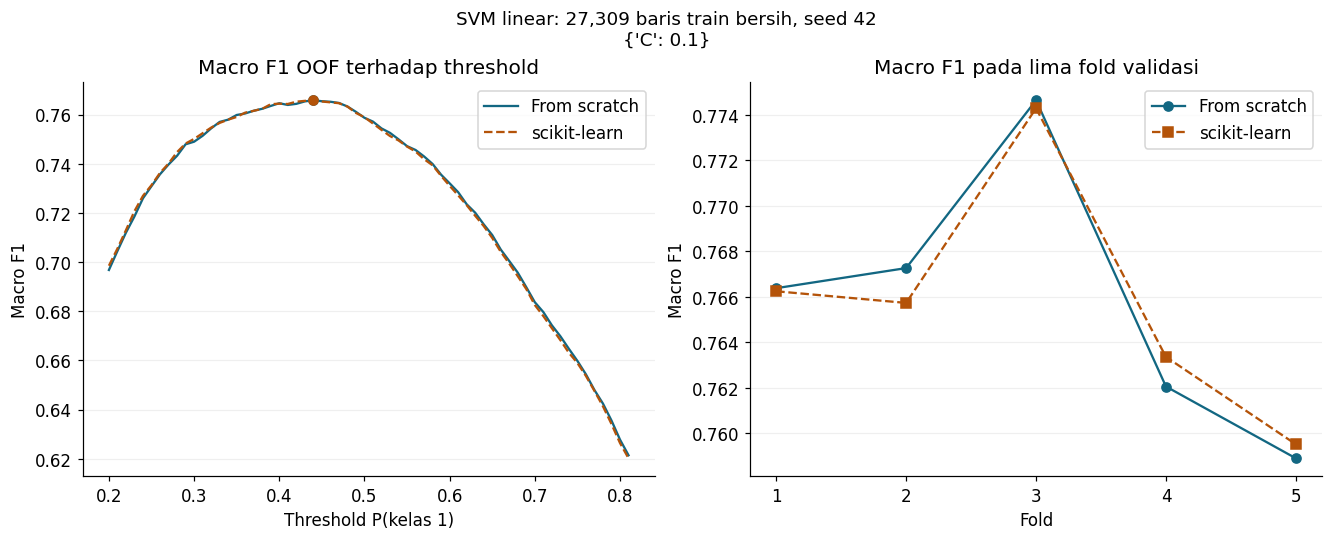

In [6]:
thresholds = np.round(np.arange(0.20, 0.81, 0.01), 2)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout='constrained')
for name, proba, result, color, style in [
    ('From scratch', oof_scratch, res_scratch, '#126782', '-'),
    ('scikit-learn', oof_sklearn, res_sklearn, '#b45309', '--'),
]:
    axes[0].plot(thresholds, [macro_f1(y, proba >= t) for t in thresholds],
                 label=name, color=color, linestyle=style)
    axes[0].scatter(result['threshold'], result['oof_macro_f1'], color=color, zorder=3)
axes[0].set(title='Macro F1 OOF terhadap threshold', xlabel='Threshold P(kelas 1)',
            ylabel='Macro F1')
axes[0].legend()
axes[1].plot(per_fold['fold'], per_fold['from_scratch'], 'o-',
             color='#126782', label='From scratch')
axes[1].plot(per_fold['fold'], per_fold['sklearn'], 's--',
             color='#b45309', label='scikit-learn')
axes[1].set(title='Macro F1 pada lima fold validasi', xlabel='Fold', ylabel='Macro F1',
            xticks=range(1, N_FOLDS + 1))
axes[1].legend()
for ax in axes:
    ax.grid(axis='y', alpha=0.2)
fig.suptitle(f'SVM {KERNEL}: {len(y):,} baris train bersih, seed {SEED}\n{best_params}',
             fontsize=12)
FIG_PATH.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(FIG_PATH, dpi=150)
plt.show()

## Catatan hasil

C=1 memperoleh skor screening tertinggi, tetapi menghasilkan dua peringatan pada
training/kalibrasi. Aturan seleksi mensyaratkan lima model utama konvergen dan
tanpa peringatan, sehingga C=0,1 dipilih untuk evaluasi penuh.

Pada konfigurasi terpilih, kurva threshold from scratch dan scikit-learn hampir
berimpit. Hasil ini menunjukkan kesesuaian pada eksperimen ini, bukan pembuktian
untuk seluruh konfigurasi SVM. Peningkatan OOF terhadap baseline linear kecil;
hasilnya belum menjadi alasan untuk mengganti baseline Decision Tree tim.

Screening parameter dan pemilihan threshold memakai data pengembangan. OOF ini
bukan evaluasi test independen; grid kecil ini juga belum mencakup seluruh pilihan
C. Prediksi test dan CSV lokal dihasilkan pada bagian akhir; tidak ada pengiriman otomatis ke Kaggle.


## Training final dan data test

Satu model from scratch dilatih pada seluruh
train bersih dengan parameter terpilih. Threshold berasal dari hasil OOF.
Bagian ini menambah satu training final setelah evaluasi; bukan mengulang 5-fold.
ID dan format input diperiksa sebelum training dimulai.


In [ ]:
test_raw = pd.read_csv(ROOT / 'data' / 'test.csv', dtype={'id': str})
sample = pd.read_csv(ROOT / 'data' / 'sample_submission.csv', dtype={'id': str})
assert list(sample.columns) == ['id', TARGET]
assert test_raw['id'].notna().all() and test_raw['id'].is_unique
assert sample['id'].is_unique and test_raw['id'].equals(sample['id'])

prep_final = SVMPreprocessor()
X_train = prep_final.fit_transform(train)
X_test = prep_final.transform(test_raw)
assert TARGET not in X_train.columns and 'id' not in X_train.columns
assert X_train.columns.equals(X_test.columns)
assert np.isfinite(X_train.to_numpy()).all() and np.isfinite(X_test.to_numpy()).all()
threshold = res_scratch['threshold']
started = time.perf_counter()
with threadpool_limits(limits=1):
    model_final = SVM(**BASE_PARAMS, **best_params).fit(X_train, y)
print(f'Training final: {time.perf_counter() - started:.1f} detik; '
      f'iterasi: {model_final.n_iter_}; konvergen: {model_final.converged_}; '
      f'threshold: {threshold}')

## Save dan load model

Preprocessor, model, dan threshold disimpan dalam satu bundle lalu dimuat kembali.


In [ ]:
save_model({'preprocessor': prep_final, 'model': model_final,
            'threshold': threshold}, MODEL_PATH)
bundle = load_model(MODEL_PATH)
print('Model tersimpan:', MODEL_PATH.relative_to(ROOT))

## Prediksi test dan ekspor CSV

Data test hanya di-transform dengan preprocessor dari train. Hasil load harus
menghasilkan prediksi yang sama. CSV siap diunggah manual ke kompetisi setelah
semua sel selesai dijalankan; tidak ada submission otomatis.


In [ ]:
with threadpool_limits(limits=1):
    test_pred = bundle['model'].predict(bundle['preprocessor'].transform(test_raw),
                                        threshold=bundle['threshold'])
    expected_pred = model_final.predict(X_test, threshold=threshold)
np.testing.assert_array_equal(test_pred, expected_pred)
assert test_pred.shape == (len(test_raw),) and np.isin(test_pred, [0, 1]).all()
submission = pd.DataFrame({'id': test_raw['id'], TARGET: test_pred})
assert submission.shape == sample.shape and submission.columns.equals(sample.columns)
assert submission['id'].equals(sample['id'])
SUB_PATH.parent.mkdir(parents=True, exist_ok=True)
submission.to_csv(SUB_PATH, index=False)
pd.testing.assert_frame_equal(submission, pd.read_csv(SUB_PATH, dtype={'id': str}))
print('CSV siap:', SUB_PATH.relative_to(ROOT), '| baris:', len(submission))
display(submission.head())